# Задача

На семинаре мы рассмотрели вариант **безусловной** генерации с помощью диффузионки.

В этой домашке мы решаем задачу **условной** генерации изображений на датасете [Flowers102](https://pytorch.org/vision/stable/generated/torchvision.datasets.Flowers102.html#torchvision.datasets.Flowers102). В качестве условия будет выступать метка класса.

Кроме того, нужно будет реализовать алгоритм, улучшеющий качество сэмплинга [**Classifier-Free Guidance**](https://arxiv.org/pdf/2207.12598)

# Что делаем?

Большая часть кода уже реализована. Обучать диффузионку в этой домашке не нужно.

В рамках домашки вам будет нужно
* Восстановить вычисления для блока с аттеншном на среднем слое `Unet`'а
* Восстановить метод `add_noise` `NoiseScheduler`'а для прямого процесса диффузии
* Восстановить метод `step` `NoiseScheduler`'а для обратного процесса диффузии с использованием [**Classifier-Free Guidance**](https://arxiv.org/pdf/2207.12598)
* Протестировать семплинг с разными значениями `classifier_free_guidance_scale`

# Что не делаем?

Не надо обучать модель. Она довольно долго обучается -- используем предобученную.



In [ ]:
from torchvision.datasets import Flowers102
import torchvision.transforms as transformsv1

import torch.nn as nn
from torch.optim import Adam
import torch
import torch.utils.data
from torch.utils.data import DataLoader

from tqdm import tqdm

import matplotlib.pyplot as plt

In [ ]:
!pip install -q pytorch-fid

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.3/21.3 MB 56.8 MB/s eta 0:00:00


In [ ]:
!pip install -q scipy==1.11.1 # https://github.com/bioinf-jku/TTUR/issues/4#issuecomment-1907223546

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 36.3/36.3 MB 21.6 MB/s eta 0:00:00
  Attempting uninstall: scipy
    Found existing installation: scipy 1.11.4
    Uninstalling scipy-1.11.4:
      Successfully uninstalled scipy-1.11.4


In [ ]:
from torchvision.utils import save_image
from pytorch_fid import fid_score

In [ ]:
resize_transform = transformsv1.Resize([ 32, 32 ])
transforms = transformsv1.Compose([
    resize_transform,
    transformsv1.ToTensor(),
    transformsv1.Normalize(0.5, 0.5),
])

flowers_dataset = Flowers102("./Flowers102", download=True, transform=transforms)

len(flowers_dataset)

100%|██████████| 344862509/344862509 [00:12<00:00, 28571586.61it/s]


Extracting Flowers102/flowers-102/102flowers.tgz to Flowers102/flowers-102


100%|██████████| 502/502 [00:00<00:00, 616917.85it/s]


100%|██████████| 14989/14989 [00:00<00:00, 10122109.59it/s]


1020

In [ ]:
!mkdir Flowers102/flowers-102-32x32

mkdir: cannot create directory ‘Flowers102/flowers-102-32x32’: File exists


In [ ]:
# Заранее подготовим ресайзнутые изображения датасета для оценки качества генерации
RESIZED_TARGET_IMAGES = 'Flowers102/flowers-102-32x32'

for i, dataset_item in enumerate(Flowers102("./Flowers102", download=True, transform=resize_transform)):
    image, class_label = dataset_item
    image.save(RESIZED_TARGET_IMAGES + f'/{i}.jpg' )

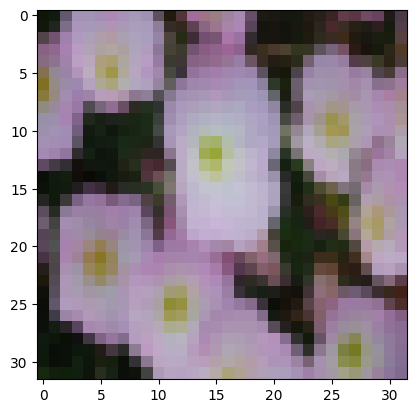

In [ ]:
plt.imshow((flowers_dataset[0][0] + 1).permute(1, 2, 0) / 2)

In [ ]:
flowers_dataset[0][0].shape

torch.Size([3, 32, 32])

## DDPM

## Basic Block

In [ ]:
import math

import torch
import torch.nn as nn
import torch.nn.functional as F

def unsqueeze_to(tensor, target_ndim):
    assert tensor.ndim <= target_ndim
    while tensor.ndim < target_ndim:
        tensor = tensor.unsqueeze(-1)
    return tensor

def unsqueeze_as(tensor, target_tensor):
    assert tensor.ndim <= target_tensor.ndim
    while tensor.ndim < target_tensor.ndim:
        tensor = tensor.unsqueeze(-1)
    return tensor


class BasicBlock(nn.Module):
    """
    Базовый блок со сверточными слоями
    котроый будет использоваться в Unet
    """

    def __init__(self, in_c, out_c, time_c, disable_last_non_linearity=False):
        super().__init__()

        self.disable_last_non_linearity = disable_last_non_linearity

        self.conv1 = nn.Conv2d(in_c, out_c, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(out_c)
        self.conv2 = nn.Conv2d(out_c, out_c, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(out_c)
        self.mlp_time = nn.Sequential(
            nn.Linear(time_c, time_c),
            nn.SiLU(),
            nn.Linear(time_c, out_c),
        )
        if in_c == out_c:
            self.shortcut = nn.Identity()
        else:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_c, out_c, kernel_size=1),
                nn.BatchNorm2d(out_c)
            )

    def forward(self, x, t):
        out = self.conv1(x)
        out = self.bn1(out)
        out = F.silu(out + unsqueeze_as(self.mlp_time(t), x))
        out = self.conv2(out)
        out = self.bn2(out)
        out = out + self.shortcut(x)
        if not self.disable_last_non_linearity:
            out = F.silu(out)
        return out


## Transformer Block

In [ ]:
# Важно!
# Эта ячейка во время автогрейдинга скопируется в отдельный файлик для запуска тестов
# Не рекомендую менять название класса, название методов, сигнатуру методов
# Не рекомендуется добавлять дополнительные импорты

# В этой ячейке вам предстоит восстановить вычисления forward для сердца нашего Unet'а
# Срединного блока с механизмом внимания

import torch
import torch.nn as nn

def apply_pixel_positional_embeddings(x, pixel_positional_embeddings_layer):
    """
    x ~ [ bs, embed_dim, spatial_pixels, spatial_pixels ] -- картинка или фича-мапа на скрытом слое
    pixel_positional_embeddings_layer: nn.Embedding -- класс позиционных эмбэддингов. Количество эмбэддингов должно быть равно (spatial_pixels ** 2)
    """

    spatial_pixels = x.shape[-1]
    assert x.shape[-2] == spatial_pixels, f'x ~ {x.shape}'

    pixel_indices = torch.arange(0, spatial_pixels**2, device=x.device, dtype=torch.long)
    pixel_positional_embeddings = pixel_positional_embeddings_layer(pixel_indices) # [ spatial_pixels**2, embed_dim ]

    pixel_positional_embeddings = pixel_positional_embeddings.reshape(1, -1, spatial_pixels, spatial_pixels) # [ 1, embed_dim, spatial_pixels, spatial_pixels ]
    pixel_positional_embeddings = pixel_positional_embeddings.repeat(x.shape[0], 1, 1, 1) # [ bs, embed_dim, spatial_pixels, spatial_pixels ]

    return x + pixel_positional_embeddings

class TransformerBlock(nn.Module):

    def __init__(self, spatial_pixels, hidden_dim, num_heads=8, condition_dim=128):
        super().__init__()

        self.hidden_dim = hidden_dim
        self.spatial_pixels = spatial_pixels

        self.pixel_positional_embeddings = nn.Embedding(spatial_pixels**2, hidden_dim)

        self.self_attention_norm = nn.LayerNorm(hidden_dim)
        self.self_attention      = nn.MultiheadAttention(hidden_dim, num_heads=8, batch_first=True)

        self.cross_attention_norm = nn.LayerNorm(hidden_dim)
        self.cross_attention      = nn.MultiheadAttention(hidden_dim, num_heads=num_heads, batch_first=True)

        self.out = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.SiLU(),
            nn.Linear(hidden_dim // 2, hidden_dim),
        )
        self.out_norm = nn.LayerNorm(hidden_dim)

        self.condition_projection = nn.Sequential(
            nn.Linear(condition_dim, condition_dim // 2),
            nn.SiLU(),
            nn.Linear(condition_dim // 2, hidden_dim),
        )

        return

    def forward(self, x, timesteps_embeds, condition_embeddings=None):
        # x                    ~ [ bs, hidden_dim, spatial_pixels, spatial_pixels ]
        # condition_embeddings ~ [ bs, 1, condition_dim ]
        # timesteps_embeds     ~ [ bs, hidden_dim ]  -- не используются

        x = apply_pixel_positional_embeddings(x, self.pixel_positional_embeddings)

        x = x.flatten(2)                 # [ bs, hidden_dim, spatial_pixels * spatial_pixels ]
        x = x.permute(0, 2, 1)           # [ bs, spatial_pixels * spatial_pixels, hidden_dim ]

        x_before_self_attention = x
        x, _ = self.self_attention(x, x, x, need_weights=False)
        x = self.self_attention_norm(x + x_before_self_attention)

        condition_embeddings = self.condition_projection(condition_embeddings) # [ bs, 1, hidden_dim ]

        x_before_cross_attention = x
        x, _ = self.cross_attention(
            query=x,
            key=condition_embeddings,
            value=condition_embeddings,
            need_weights=False
        )
        x = self.cross_attention_norm(x + x_before_cross_attention)

        x = self.out_norm(self.out(x) + x)

        x = x.unflatten(1, (self.spatial_pixels, self.spatial_pixels))  # [ bs, spatial_pixels, spatial_pixels, hidden_dim ]
        x = x.permute(0, 3, 1, 2)                                        # [ bs, hidden_dim, spatial_pixels, spatial_pixels ]

        return x


In [ ]:
!rm test_transformer_block.pt
!wget https://storage.yandexcloud.net/fintech-dl-hse-hwdata/test_transformer_block.pt

rm: cannot remove 'test_transformer_block.pt': No such file or directory
--2024-05-22 19:31:40--  https://storage.yandexcloud.net/fintech-dl-hse-hwdata/test_transformer_block.pt
Resolving storage.yandexcloud.net (storage.yandexcloud.net)... 213.180.193.243, 2a02:6b8::1d9
Connecting to storage.yandexcloud.net (storage.yandexcloud.net)|213.180.193.243|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 28246 (28K) [application/x-www-form-urlencoded]
Saving to: ‘test_transformer_block.pt’

test_transformer_bl 100%[===================>]  27.58K  --.-KB/s    in 0.1s    

2024-05-22 19:31:41 (196 KB/s) - ‘test_transformer_block.pt’ saved [28246/28246]



In [ ]:
@torch.no_grad()
def generate_transformer_block_data():
    # этот метод оставил для примера - как были сгенерированы данные в
    #
    #
    # необходимости запускать этот метод нет!

    bs = 3
    hidden_dim = 16
    spatial_pixels = 4

    transformer_block = TransformerBlock(spatial_pixels=spatial_pixels, hidden_dim=hidden_dim, condition_dim=16)

    x = torch.rand([ bs, hidden_dim, spatial_pixels, spatial_pixels ])
    condition_embeddings = torch.rand([ bs, 1, hidden_dim ])
    timesteps_embeds = torch.rand([ bs, hidden_dim ])

    out = transformer_block.forward(x, timesteps_embeds, condition_embeddings=condition_embeddings)

    assert out.shape == x.shape

    test_transformer_block_data = {
        # Transformer Block State
        "transformer_block_state": transformer_block.state_dict(),

        # Inputs
        "x": x,
        "timesteps_embeds": timesteps_embeds,
        "condition_embeddings": condition_embeddings,

        # Exoected Out
        "expected_out": out,
    }

    # Не стоит удалять комментарий ниже, чтобы случайно не перезатереть скачанный файлик с данными для теста
    # torch.save(test_transformer_block_data, "test_transformer_block.pt")

@torch.no_grad()
def test_transformer_block():

    # Arrange
    bs = 3
    hidden_dim = 16
    spatial_pixels = 4
    transformer_block = TransformerBlock(spatial_pixels=spatial_pixels, hidden_dim=hidden_dim, condition_dim=16)

    # Transformer Block State
    test_transformer_block_data = torch.load("test_transformer_block.pt")

    # Inputs
    x = test_transformer_block_data['x']
    timesteps_embeds = test_transformer_block_data['timesteps_embeds']
    condition_embeddings = test_transformer_block_data['condition_embeddings']

    # Expected Output
    transformer_block_state = test_transformer_block_data['transformer_block_state']
    transformer_block.load_state_dict(transformer_block_state)

    expected_out = test_transformer_block_data['expected_out']

    # Act
    out = transformer_block.forward(x, timesteps_embeds, condition_embeddings=condition_embeddings)

    assert torch.allclose(out, expected_out, atol=1e-4)

test_transformer_block()
print("ok")

ok


## Unet

In [ ]:
# В этой ячейке не нужно ничего дополнять.
# Но хорошо бы изучить код этой ячейки, чтобы понять, как используется
# условие (метка класса), трансформерные блоки и представления таймстемпов

import torch

class UNet(nn.Module):
    def __init__(self, in_dim, embed_dim, dim_scales, need_attentions, num_timesteps=1000, num_classes=10, spatial_pixels=0):
        """
        in_dim           - количество входных каналов изображения (обычно = 3)
        embed_dim        - размерность каналов для первой фича-мапы
        dim_scales       - тупл, который определяет на сколько будет увеличиваться размерность каналов фича-мап на каждом уровне Unet'а
        need_attentions  - `List[bool]` такой же длинны как `dim_scales`.
                            Определяет, нужно ли использовать механизм внимания на соответствующем уровне Unet'а.
                            Если значение равно True, то модуль внимания добавится
                            на соответствующем уровне Unet'а как при проходе вниз, так и проходе вверх.
                            Обычно полный аттешн включают только на нижних уровнях Unet тк там наименьшая пространственная
                            размерность фича-мапы (меньше высота и ширина) и вычислить атеншн можно относительно дешево.
        num_timesteps    - количетво таймстепов
        num_classes      - количество классов. Используется для условной генерации.
                           Условность будет работать с помощью механизма cross-attention в блоках внимания.
        spatial_pixels   - Пространственная размерность входной картинки, в домашке будем генерить картинки 32x32
        """

        super().__init__()

        self.num_timesteps = num_timesteps
        self.embeddin_dim_low = embed_dim*dim_scales[-1]
        self.embed_dim = embed_dim
        self.spatial_pixels = spatial_pixels

        # вычисляем пространственную размерность на нижнем слое
        num_downsamplings = (len(dim_scales) - 1)
        spatial_pixels_low = int(spatial_pixels // (2**num_downsamplings) )
        self.spatial_pixels_low = spatial_pixels_low

        self.init_embed = nn.Conv2d(in_dim, embed_dim, kernel_size=1)
        self.time_embed = nn.Embedding(num_timesteps, embed_dim)

        self.num_classes = num_classes
        self.null_class_index = num_classes # используется для unconditional генерации для реализации classifier-free-guidance

        self.condition_dim = self.embeddin_dim_low
        self.condition_embeddings = nn.Embedding(num_classes + 1, self.condition_dim) # +1 for unconditional

        self.pixel_positional_embeddings = nn.Embedding(spatial_pixels**2, embed_dim)

        # Пример:
        #   in_dim=1, embed_dim=32, dim_scales=(1, 2, 4, 8) => all_dims=(32, 32, 64, 128, 256)
        all_dims = (embed_dim, *[embed_dim * s for s in dim_scales])
        all_need_attention = (False, *need_attentions)
        self.all_dims = all_dims

        # Down blocks
        self.down_blocks = nn.ModuleList()
        current_spatial_pixels = spatial_pixels

        for idx, (in_c, out_c, need_attention) in enumerate(zip(all_dims[:-1], all_dims[1:], need_attentions)):
            is_last = (idx == len(all_dims) - 2)
            if not is_last:
                last_conv_module = nn.Conv2d(in_c, out_c, kernel_size=3, stride=2, padding=1)
            else:
                last_conv_module = nn.Conv2d(in_c, out_c, kernel_size=1)

            block_attention = nn.Identity()
            if need_attention:
                block_attention = TransformerBlock(spatial_pixels=current_spatial_pixels, hidden_dim=in_c, condition_dim=self.condition_dim)

            self.down_blocks.extend(nn.ModuleList([
                BasicBlock(in_c, in_c, embed_dim),
                BasicBlock(in_c, in_c, embed_dim),
                block_attention,
                last_conv_module,
            ]))

            if not is_last:
                current_spatial_pixels = current_spatial_pixels // 2

        # Mid blocks
        self.mid_blocks = nn.ModuleList([
            BasicBlock(all_dims[-1], all_dims[-1], embed_dim),
            TransformerBlock(spatial_pixels=self.spatial_pixels_low, hidden_dim=self.embeddin_dim_low, condition_dim=self.condition_dim),
            BasicBlock(all_dims[-1], all_dims[-1], embed_dim),
        ])

        # Up blocks
        self.up_blocks = nn.ModuleList()
        current_spatial_pixels = self.spatial_pixels_low
        for idx, (in_c, out_c, skip_c, need_attention) in enumerate(zip(all_dims[::-1][:-1], all_dims[::-1][1:], all_dims[:-1][::-1], need_attentions[::-1])):
            is_last = (idx == len(all_dims) - 2)
            if not is_last:
                last_conv_module =  nn.Sequential(
                    nn.Upsample(scale_factor=2),
                    nn.Conv2d(in_c, out_c, kernel_size=3, padding=1),
                )
            else:
                last_conv_module = nn.Conv2d(in_c, out_c, kernel_size=1)

            block_attention = nn.Identity()
            if need_attention:
                block_attention = TransformerBlock(spatial_pixels=current_spatial_pixels, hidden_dim=in_c, condition_dim=self.condition_dim)

            self.up_blocks.extend(nn.ModuleList([
                BasicBlock(in_c + skip_c, in_c, embed_dim),
                BasicBlock(in_c + skip_c, in_c, embed_dim),
                block_attention,
                last_conv_module,
            ]))
            if not is_last:
                current_spatial_pixels = current_spatial_pixels * 2


        # Out blocks
        self.out_blocks = nn.ModuleList([
            BasicBlock(embed_dim * 2, embed_dim, embed_dim),
            nn.Conv2d(embed_dim, in_dim, kernel_size=1),
        ])


    def process_block(self, block, x, t, condition_embeddings):
        if isinstance(block, BasicBlock):
            x = block(x, t)
        elif isinstance(block, TransformerBlock):
            x = block(x, t, condition_embeddings=condition_embeddings)
        else:
            x = block(x)
        return x


    def forward(self, x, condition, t):
        """
        x          ~ [bs, 3, spatial_dim, spatial_dim]  -- зашумленное изображение, для которого делаем обратный шаг диффузи
        condition  ~ [bs] dtype=torch.long              -- числовая метка, соответсвующая классу цветка
                                                           метка 102 соответствует безусловной генерации. С этой меткой может прийти изображение любого класса.
        t          ~ [bs] dtype=torch.long              -- таймстеп процесса диффузии, для которого делаем обратный шаг диффузии
        """

        x = self.init_embed(x)
        x = apply_pixel_positional_embeddings(
            x,
            pixel_positional_embeddings_layer=self.pixel_positional_embeddings,
        )

        t = self.time_embed(t) # [ bs, embed_dim ]
        skip_conns = []
        residual = x.clone()

        condition_embeddings = self.condition_embeddings(condition) # [ bs, self.embeddin_dim_low ]
        condition_embeddings = condition_embeddings.unsqueeze(1)    # [ bs, 1, self.embeddin_dim_low ]

        for block in self.down_blocks:
            x = self.process_block(block, x, t, condition_embeddings)
            # сохраняем скип-коннекшн для блоков
            if isinstance(block, BasicBlock):
                skip_conns.append(x)

        for block in self.mid_blocks:
            x = self.process_block(block, x, t, condition_embeddings)

        for block in self.up_blocks:
            if isinstance(block, BasicBlock):
                x = torch.cat((x, skip_conns.pop()), dim=1)
            x = self.process_block(block, x, t, condition_embeddings)

        x = torch.cat((x, residual), dim=1)
        for block in self.out_blocks:
            x = self.process_block(block, x, t, condition_embeddings)

        return x


In [ ]:
# unet sanity check
spatial_pixels = 32
sample = torch.rand([5, 3, spatial_pixels, spatial_pixels])
condition = torch.zeros([5], dtype=torch.long)
timesteps = torch.ones([5], dtype=torch.long)
test_unet = UNet(in_dim=3, dim_scales=[2, 4, 8], need_attentions=[False, False, True], embed_dim=32, spatial_pixels=spatial_pixels)
test_unet.forward( sample, condition, timesteps ).shape

torch.Size([5, 3, 32, 32])

# Noise Scheduler

In [ ]:
# Важно!
# Эта ячейка во время автогрейдинга скопируется в отдельный файлик для запуска тестов
# Не рекомендую менять название класса, название методов, сигнатуру методов
# Не рекомендуется добавлять дополнительные импорты

# В текущей ячейке вам потребуется дописать реализацию `self.add_noise`, `self.step`
# Подсказки и ссылки на нужные места в исходных статьях есть в комментариях к этим методам

import os

import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader
from tqdm.auto import tqdm

import matplotlib.pyplot as plt
import numpy as np


class NoiseScheduler():
    def __init__(self,
                 num_timesteps=1000,
                 beta_start=0.0001,
                 beta_end=0.02,
                 beta_schedule="linear",
                 use_step_with_clip=False,
                 device='cpu',
                 ):

        self.num_timesteps = num_timesteps
        if beta_schedule == "linear":
            self.betas = torch.linspace(
                beta_start, beta_end, num_timesteps, dtype=torch.float32)
        elif beta_schedule == "quadratic":
            self.betas = torch.linspace(
                torch.sqrt(beta_start), torch.sqrt(beta_end), num_timesteps, dtype=torch.float32) ** 2

        self.betas = self.betas.to(device)

        self.alphas = 1.0 - self.betas
        self.alphas_cumprod = torch.cumprod(self.alphas, axis=0)
        self.alphas_cumprod_prev = F.pad(
            self.alphas_cumprod[:-1], (1, 0), value=1.)

        self.sqrt_alphas_cumprod = torch.sqrt(self.alphas_cumprod)
        self.sqrt_alphas_cumprod.to(device)
        self.sqrt_one_minus_alphas_cumprod = torch.sqrt(1 - self.alphas_cumprod)

        self.inv_sqrt_alphas = 1 / torch.sqrt(self.alphas)
        self.noise_scalers = torch.sqrt(
            self.betas * (1. - self.alphas_cumprod_prev) / (1. - self.alphas_cumprod)
        ).clip(1e-20)


    def step(self, model_output, timestep, sample, unconditional_model_output=None, classifier_free_guidance_scale=0.0, noise=None):
        """
        model_output: Tensor ~ [ bs, num_channels, spatial_size, spatial_size ]
        timestep:     int
        sample:       Tensor ~ [ bs, num_channels, spatial_size, spatial_size ]
        """

        # classifier free guidance
        if unconditional_model_output is not None:
            model_output = unconditional_model_output + classifier_free_guidance_scale * (
                model_output - unconditional_model_output
            )

        t = timestep

        betas_t = self.betas[t]
        sqrt_one_minus_alphas_cumprod_t = self.sqrt_one_minus_alphas_cumprod[t]
        inv_sqrt_alphas_t = self.inv_sqrt_alphas[t]

        # Equation 11 in DDPM
        pred_prev_sample = inv_sqrt_alphas_t * (
            sample - (betas_t / sqrt_one_minus_alphas_cumprod_t) * model_output
        )

        variance = 0
        if t > 0:
            if noise is None:
                noise = torch.randn_like(model_output)

            variance = noise * self.noise_scalers[t]

        pred_prev_sample = pred_prev_sample + variance

        return pred_prev_sample

    def add_noise(self, x_start, x_noise, timesteps):
        s1 = self.sqrt_alphas_cumprod[timesteps]
        s2 = self.sqrt_one_minus_alphas_cumprod[timesteps]

        s1 = s1.view(-1, 1, 1, 1)
        s2 = s2.view(-1, 1, 1, 1)

        x_noisy = s1 * x_start + s2 * x_noise

        return x_noisy

    def __len__(self):
        return self.num_timesteps

In [ ]:
!rm test_noise_scheduler_add_noise.pt test_noise_scheduler_step.pt
!wget https://storage.yandexcloud.net/fintech-dl-hse-hwdata/test_noise_scheduler_add_noise.pt
!wget https://storage.yandexcloud.net/fintech-dl-hse-hwdata/test_noise_scheduler_step.pt

rm: cannot remove 'test_noise_scheduler_add_noise.pt': No such file or directory
rm: cannot remove 'test_noise_scheduler_step.pt': No such file or directory
--2024-05-22 19:31:45--  https://storage.yandexcloud.net/fintech-dl-hse-hwdata/test_noise_scheduler_add_noise.pt
Resolving storage.yandexcloud.net (storage.yandexcloud.net)... 213.180.193.243, 2a02:6b8::1d9
Connecting to storage.yandexcloud.net (storage.yandexcloud.net)|213.180.193.243|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 28226037 (27M) [application/x-www-form-urlencoded]
Saving to: ‘test_noise_scheduler_add_noise.pt’

test_noise_schedule 100%[===================>]  26.92M  12.4MB/s    in 2.2s    

2024-05-22 19:31:48 (12.4 MB/s) - ‘test_noise_scheduler_add_noise.pt’ saved [28226037/28226037]

--2024-05-22 19:31:48--  https://storage.yandexcloud.net/fintech-dl-hse-hwdata/test_noise_scheduler_step.pt
Resolving storage.yandexcloud.net (storage.yandexcloud.net)... 213.180.193.243, 2a02:6b8::1d9
Con

In [ ]:
@torch.no_grad()
def generate_test_noise_scheduler_add_noise_data():
    # этот метод оставил для примера - как были сгенерированы данные в
    # https://storage.yandexcloud.net/fintech-dl-hse-hwdata/test_noise_scheduler_add_noise.pt
    #
    # необходимости запускать этот метод нет!

    ns = NoiseScheduler()

    batch_size = len(ns)
    num_channels = 3
    spatial_size = 28
    x_start = torch.rand([ batch_size, num_channels, spatial_size, spatial_size ]) * 2 - 1
    x_noise = torch.randn_like(x_start)

    timesteps = torch.arange(len(ns))

    noisy_sample = ns.add_noise(x_start, x_noise, timesteps)

    test_noise_scheduler_add_noise_data = {
        "x_start": x_start,
        "x_noise": x_noise,
        "noisy_sample": noisy_sample,
    }

    # Не стоит удалять комментарий ниже, чтобы случайно не перезатереть скачанный файлик с данными для теста
    # torch.save(test_noise_scheduler_add_noise_data, "test_noise_scheduler_add_noise.pt")

@torch.no_grad()
def test_noise_scheduler_add_noise():
    ns = NoiseScheduler()

    test_noise_scheduler_add_noise_data = torch.load("test_noise_scheduler_add_noise.pt")
    x_start = test_noise_scheduler_add_noise_data['x_start']
    x_noise = test_noise_scheduler_add_noise_data['x_noise']

    expected_noisy_sample = test_noise_scheduler_add_noise_data['noisy_sample']

    timesteps = torch.arange(len(ns))

    noisy_sample = ns.add_noise(x_start, x_noise, timesteps)

    assert torch.allclose(noisy_sample, expected_noisy_sample, atol=1e-4)

test_noise_scheduler_add_noise()
print("ok")

ok


In [ ]:
@torch.no_grad()
def generate_test_noise_scheduler_step_data():
    # этот метод оставил для примера - как были сгенерированы данные в
    # https://storage.yandexcloud.net/fintech-dl-hse-hwdata/test_noise_scheduler_step.pt
    #
    # необходимости запускать этот метод нет!

    ns = NoiseScheduler()

    batch_size = 7
    num_channels = 3
    spatial_size = 28

    sample = torch.rand([ batch_size, num_channels, spatial_size, spatial_size ]) * 2 - 1
    model_output = torch.randn_like(sample)
    unconditional_model_output = torch.randn_like(model_output)
    classifier_free_guidance_scale = 1.0

    noise = torch.randn_like(model_output)

    test_noise_scheduler_step_data = {
        "sample": sample,
        "model_output": model_output,
        "unconditional_model_output": unconditional_model_output,
        "classifier_free_guidance_scale": classifier_free_guidance_scale,
        "noise": noise,
    }

    # Обратите внимание, в этом тесте не настоящий семплинг --
    # Для того чтобы минимизировать возможную накопленную ошибку вычислений
    # В .step каждый раз передается одно и то же значение model_output, sample
    for timestep in range(len(ns)):
        noisy_sample = ns.step(model_output, timestep, sample, unconditional_model_output=unconditional_model_output, classifier_free_guidance_scale=classifier_free_guidance_scale, noise=noise)

        test_data_key = f"noisy_sample_{timestep}"
        test_noise_scheduler_step_data[test_data_key] = noisy_sample

    # Не стоит удалять комментарий ниже, чтобы случайно не перезатереть скачанный файлик с данными для теста
    # torch.save(test_noise_scheduler_step_data, "test_noise_scheduler_step.pt")
    return

@torch.no_grad()
def test_noise_scheduler_step():
    ns = NoiseScheduler()

    batch_size = 7
    num_channels = 3
    spatial_size = 28

    test_noise_scheduler_step_data = torch.load("test_noise_scheduler_step.pt")

    sample = test_noise_scheduler_step_data['sample']
    model_output = test_noise_scheduler_step_data['model_output']
    unconditional_model_output = test_noise_scheduler_step_data['unconditional_model_output']
    classifier_free_guidance_scale = test_noise_scheduler_step_data['classifier_free_guidance_scale']

    noise = test_noise_scheduler_step_data['noise']

    # Обратите внимание, в этом тесте не настоящий семплинг --
    # Для того чтобы минимизировать возможную накопленную ошибку вычислений
    for timestep in range(len(ns)):
        noisy_sample = ns.step(model_output, timestep, sample, unconditional_model_output=unconditional_model_output, classifier_free_guidance_scale=classifier_free_guidance_scale, noise=noise)

        test_data_key = f"noisy_sample_{timestep}"
        expected_noisy_sample = test_noise_scheduler_step_data[test_data_key]
        assert torch.allclose(expected_noisy_sample, noisy_sample, atol=1e-3)

    return

test_noise_scheduler_step()
print("ok")

ok


In [ ]:
# Тут ничего не нужно изменять

from dataclasses import dataclass

@dataclass
class TrainingConfig:
    experiment_name: str = "flowers-classifier-free"

    train_batch_size: int = 50
    eval_batch_size: int = 16
    num_epochs: int = 1000
    learning_rate: float = 3e-4

    spatial_pixels = 32
    num_classes = 102
    num_image_channels = 3

    num_timesteps: int = 1000
    beta_schedule: str = "linear"
    embedding_size: int = 64
    dim_scales = (1, 2, 4, 4, 4)
    need_attentions = (False, False, True, True, True)

    # https://arxiv.org/pdf/2207.12598
    # Classifier-Free Guidance Scale
    classifier_free_guidance_scale = 1
    unconditional_probability = 0.1

    save_images_step: int = 20


In [ ]:
config = TrainingConfig()

outdir = f"exps/{config.experiment_name}"
imgdir = f"{outdir}/images"
fid_imgdir = f"{outdir}/fid_images"
os.makedirs(imgdir, exist_ok=True)
os.makedirs(fid_imgdir, exist_ok=True)

## Метод сэмплинга

In [ ]:
# Тут тоже ничего не нужно изменять

@torch.no_grad()
def evaluate_diffusion(model, noise_scheduler, config, epoch=None, sample=None, timesteps_offset=0, condition_labels=None):
    model.eval()

    if sample is None:
        sample = torch.randn(config.eval_batch_size, config.num_image_channels, config.spatial_pixels, config.spatial_pixels, device=device)

    timesteps = list(range(len(noise_scheduler)))[::-1][timesteps_offset:]

    eval_batch_size = config.eval_batch_size

    sample = sample.repeat(2, 1, 1, 1) # duplicate batch dimension for unconditional generation
    eval_batch_size = eval_batch_size * 2
    if condition_labels is not None:
        condition = condition_labels.to(device)
    else:
        condition = torch.full([config.eval_batch_size], model.null_class_index, device=device, dtype=torch.long)
    unconditional = torch.full([config.eval_batch_size], model.null_class_index, device=device, dtype=torch.long)

    condition = torch.cat([condition, unconditional])

    t_tensor = torch.zeros([eval_batch_size], device=device, dtype=torch.long)
    for i, t in enumerate(tqdm(timesteps)):
        t_tensor.fill_(t)
        unconditional_model_output = None

        model_output = model(sample, condition, t_tensor)
        model_output, unconditional_model_output = torch.chunk(model_output, 2, dim=0)
        sample, _ = torch.chunk(sample, 2, dim=0)

        sample = noise_scheduler.step(
            model_output, t, sample,
            unconditional_model_output=unconditional_model_output,
            classifier_free_guidance_scale=config.classifier_free_guidance_scale,
        )

        sample = sample.repeat(2, 1, 1, 1)

    sample, _ = torch.chunk(sample, 2, dim=0)
    sample = sample / 2 + 0.5
    normalized_sample = sample
    sample = sample.clamp(0.0, 1.0)

    sample_plt_layout = sample.permute(0, 2, 3, 1)
    frame_batch = sample_plt_layout.detach().cpu().numpy()

    print("Saving images...")
    if epoch is None:
        epoch = "evaluation"

    epoch_fid_imgdir = fid_imgdir + f'/{epoch}_cfgs_{config.classifier_free_guidance_scale}'
    os.makedirs(epoch_fid_imgdir, exist_ok=True)
    print("fid_imgdir", epoch_fid_imgdir)

    for image_idx, frame in enumerate(sample.detach().cpu()):
        save_image(frame, epoch_fid_imgdir + f'/{image_idx}.jpg')

    fid_value = fid_score.calculate_fid_given_paths(
        [ RESIZED_TARGET_IMAGES, epoch_fid_imgdir ], batch_size=50, dims=2048, device=device
    )
    print("fid score", fid_value)

    return frame_batch, fid_value

# Запустим генерацию

Если вы все реализовали правильно, можно посмотреть на примере генерации конкретного класса цветка, как classifier-free-guidance
влияет на сгенерированные сэмплы.


In [ ]:
def sample_cfg(model, noise_scheduler, config, generate_class=None, device='cpu'):
    if generate_class is None:
        generate_class = config.num_classes # если класс не передали, используем класс для безусловной генерациии

    condition = torch.full(size=[config.eval_batch_size], fill_value=generate_class, device=device, dtype=torch.long)

    ns_frames, _ = evaluate_diffusion(
        model,
        noise_scheduler,
        config,
        epoch=f"eval",
        condition_labels=condition,
    );

    f, axs = plt.subplots(2, 8)
    f.set_size_inches(8, 2)

    axs = axs.flatten()
    for i, ax in enumerate(axs):
        ax.imshow(ns_frames[i])

    return ns_frames


In [ ]:
# Скачаем предобученные веса
!rm model.pth
!wget https://storage.yandexcloud.net/fintech-dl-hse-hwdata/model.pth

rm: cannot remove 'model.pth': No such file or directory
--2024-05-22 19:31:59--  https://storage.yandexcloud.net/fintech-dl-hse-hwdata/model.pth
Resolving storage.yandexcloud.net (storage.yandexcloud.net)... 213.180.193.243, 2a02:6b8::1d9
Connecting to storage.yandexcloud.net (storage.yandexcloud.net)|213.180.193.243|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 109096014 (104M) [application/x-www-form-urlencoded]
Saving to: ‘model.pth’

model.pth           100%[===================>] 104.04M  18.1MB/s    in 6.7s    

2024-05-22 19:32:07 (15.5 MB/s) - ‘model.pth’ saved [109096014/109096014]



In [ ]:
config = TrainingConfig()

device = 'cuda' if torch.cuda.is_available() else 'cpu'
noise_scheduler = NoiseScheduler(device=device)

model = UNet(
    in_dim=3,
    embed_dim=config.embedding_size,
    dim_scales=config.dim_scales,
    spatial_pixels=config.spatial_pixels,
    num_classes=config.num_classes,
    need_attentions=config.need_attentions,
)

# Подгружаем веса
model_state = torch.load(f"./model.pth")
model.load_state_dict(model_state)

model.to(device)

generation_class = 5
config.eval_batch_size = 16

**Безусловная генерация**

Должны сгенериться цветы разных классов

  0%|          | 0/1000 [00:00<?, ?it/s]

Saving images...
fid_imgdir exps/flowers-classifier-free/fid_images/eval_cfgs_0.0


100%|██████████| 21/21 [00:04<00:00,  4.87it/s]


100%|██████████| 1/1 [00:00<00:00,  8.31it/s]


fid score 233.70445216045033


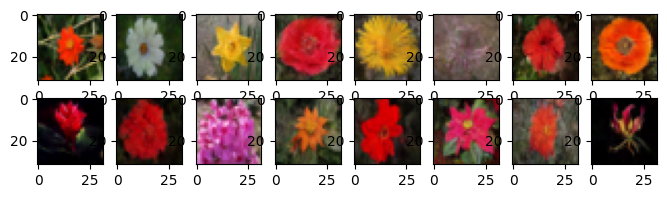

In [ ]:
config.classifier_free_guidance_scale = 0.0
sample_cfg(model, noise_scheduler, config, generate_class=None);

**Условная генерация для класса `generation_class` с разными значениями CFG**

  0%|          | 0/1000 [00:00<?, ?it/s]

Saving images...
fid_imgdir exps/flowers-classifier-free/fid_images/eval_cfgs_0.0


100%|██████████| 21/21 [00:04<00:00,  4.84it/s]


100%|██████████| 1/1 [00:00<00:00,  7.44it/s]


fid score 282.3931294155938


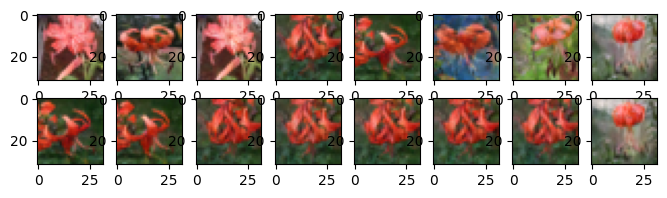

In [ ]:
config.classifier_free_guidance_scale = 0.0
sample_cfg(model, noise_scheduler, config, generate_class=generation_class);

  0%|          | 0/1000 [00:00<?, ?it/s]

Saving images...
fid_imgdir exps/flowers-classifier-free/fid_images/eval_cfgs_2.5


100%|██████████| 21/21 [00:04<00:00,  4.91it/s]


100%|██████████| 1/1 [00:00<00:00,  7.67it/s]


fid score 324.70602889480006


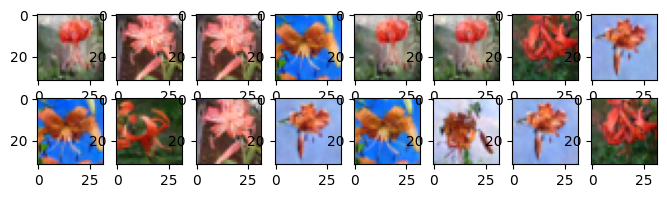

In [ ]:
config.classifier_free_guidance_scale = 2.5
sample_cfg(model, noise_scheduler, config, generate_class=generation_class);

  0%|          | 0/1000 [00:00<?, ?it/s]

Saving images...
fid_imgdir exps/flowers-classifier-free/fid_images/eval_cfgs_5.0


100%|██████████| 21/21 [00:04<00:00,  4.93it/s]


100%|██████████| 1/1 [00:00<00:00,  7.33it/s]


fid score 340.65035983447166


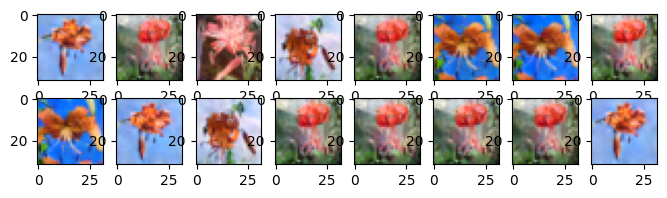

In [ ]:
config.classifier_free_guidance_scale = 5.0
sample_cfg(model, noise_scheduler, config, generate_class=generation_class);

  0%|          | 0/1000 [00:00<?, ?it/s]

Saving images...
fid_imgdir exps/flowers-classifier-free/fid_images/eval_cfgs_100.0


100%|██████████| 21/21 [00:04<00:00,  4.90it/s]


100%|██████████| 1/1 [00:00<00:00,  5.83it/s]


fid score 492.6991515169446


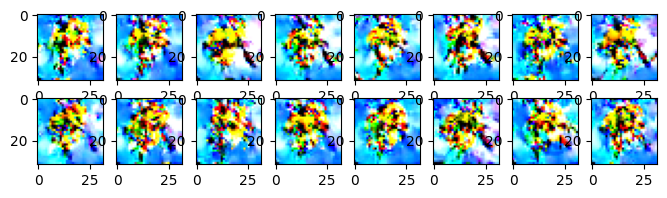

In [ ]:
config.classifier_free_guidance_scale = 100.0
sample_cfg(model, noise_scheduler, config, generate_class=generation_class);

# Вопросы на поразмышлять

### Что изменяется с увеличением `Classifier Free Guidance Scale`?

### Почему с очень большими значениями ~100 `Classifier-Free-Guidance Scale` генерится что-то странное?

### Почему при увеличении cfg-scale уменьшается разнообразие генерации?

### Мы использовали CFG для того, чтобы увеличить "похожесть" сгенерированных сэмплов и запроса - (метки класса). Что можно было бы сделать, чтобы решить обратную задачу - сделать сгенерированные сэмплы более разнообразными? Как для этого можно использовать часть `unconditional` предсказания?


----

# Что дальше?

На этом обязательная часть ДЗ закончилась.

Если тесты проходят, можете загрузить домашку на гитхаб и получить оценку от автогрейдера.

Если есть желание, можете попробовать дообучить или обучить с нуля диффузионку.
Но, скорее всего, на это потребуется значительное количество времени и ресурсов, даже для такой не очень сложной задачки.

Это не принесет вам баллов, но возможно, кому-то будет интересно)


## Трейн

In [ ]:
def load_state_dict_gracefull(model, state_dict):
    state_key_not_found = [ ]
    state_key_bad_shape = [ ]
    for n, p in model.named_parameters():
        if n not in state_dict:
            state_key_not_found.append(n)
            continue
        state_param_value = state_dict[n]
        if state_param_value.shape != p.shape:
            state_key_bad_shape.append(n)
            continue

        p.data = state_dict[n].data

    return state_key_not_found, state_key_bad_shape


In [ ]:
def train_epoch(model, noise_scheduler, config, dataloader, epoch):

    global_step = 0

    model.train()
    progress_bar = tqdm(total=len(dataloader))
    progress_bar.set_description(f"Epoch {epoch}")
    for step, batch in enumerate(dataloader):
        batch, condition = batch[0], batch[1]
        batch = batch.to(device)

        condition = condition.to(device)
        unconditional_indicies = torch.rand(condition.shape, device=device) < config.unconditional_probability
        condition[unconditional_indicies] = model.null_class_index

        noise = torch.randn(batch.shape, device=device)
        timesteps = torch.randint(
            0, noise_scheduler.num_timesteps, (batch.shape[0],), device=device
        ).long()

        noisy = noise_scheduler.add_noise(batch, noise, timesteps)

        noise_pred = model(noisy, condition, timesteps)

        loss = F.mse_loss(noise_pred, noise)
        loss.backward()

        # nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        optimizer.zero_grad()

        progress_bar.update(1)
        logs = {"loss": loss.detach().item(), "step": global_step}
        progress_bar.set_postfix(**logs)
        global_step += 1

    progress_bar.close()

    return


In [ ]:
from torch.utils.data import random_split

# flowers_dataset_part, _ = random_split(flowers_dataset, lengths=[0.1, 0.9])
flowers_dataset_part, _ = random_split(flowers_dataset, lengths=[0.99, 0.01])
len(flowers_dataset_part)

1010

In [ ]:
config = TrainingConfig()

dataloader = DataLoader(flowers_dataset_part, batch_size=config.train_batch_size, shuffle=True, drop_last=True)

model = UNet(
    in_dim=3,
    embed_dim=config.embedding_size,
    dim_scales=config.dim_scales,
    spatial_pixels=config.spatial_pixels,
    num_classes=config.num_classes,
    need_attentions=config.need_attentions,
)

model_state = torch.load(f"{outdir}/model.pth")
state_key_not_found, state_key_bad_shape = load_state_dict_gracefull(model, model_state)
print("state_key_not_found", len(state_key_not_found), "state_key_bad_shape", len(state_key_bad_shape))

device = 'cuda' if torch.cuda.is_available() else 'cpu'
# device = 'cpu'
model.to(device)

noise_scheduler = NoiseScheduler(
    num_timesteps=config.num_timesteps,
    beta_schedule=config.beta_schedule,
    device=device,
)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=config.learning_rate,
)

global_step = 0
fid_scores = []

outdir = f"exps/{config.experiment_name}"
imgdir = f"{outdir}/images"
fid_imgdir = f"{outdir}/fid_images"
os.makedirs(imgdir, exist_ok=True)
os.makedirs(fid_imgdir, exist_ok=True)


state_key_not_found 24 state_key_bad_shape 0


In [ ]:
trainable_parameters = sum(p.numel() for p in model.parameters() if p.requires_grad)

print("Training model...", trainable_parameters)

Training model... 27205507


In [ ]:
f"{outdir}/model.pth"

'exps/flowers-classifier-free-mblock-width-attention-no-linear-attention/model.pth'

In [ ]:
config.save_images_step = 100

In [ ]:
for epoch in range(config.num_epochs):

    train_epoch(model, noise_scheduler, config, dataloader, epoch=epoch)

    if epoch > 0 and epoch % config.save_images_step == 0 or epoch == config.num_epochs - 1:
        # generate data with the model to later visualize the learning process
        frame_batch, fid_value = evaluate_diffusion(model, noise_scheduler, config, epoch=epoch)
        fid_scores.append(fid_value)

print("Saving model...")
os.makedirs(outdir, exist_ok=True)
torch.save(model.state_dict(), f"{outdir}/model.pth")


Training model... 27205507


100%|██████████████████████████████████████████████████████████████████████████████| 1000/1000 [00:29<00:00, 34.01it/s]


Saving images...
fid_imgdir exps/flowers-classifier-free-mblock-width-attention-no-linear-attention/fid_images/100_cfgs_1


100%|██████████████████████████████████████████████████████████████████████████████████| 21/21 [00:04<00:00,  5.19it/s]


100%|████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00,  6.18it/s]


fid score 299.5189729009046


... (41 outputs left out)

Saving images...
fid_imgdir exps/flowers-classifier-free-mblock-width-attention-no-linear-attention/fid_images/999_cfgs_1


100%|██████████████████████████████████████████████████████████████████████████████████| 21/21 [00:04<00:00,  5.23it/s]


100%|████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00,  6.71it/s]


fid score 303.99116144220113
Saving model...
